# Hyper Instancing Meshes in a BIM Model - 4

In this multi-part project, we are attempting to reduce the memory footprint of large BIM models by consolidating duplicate geometry into one. In [part 3](hyper-instance-3.ipynb) of this notebook we were able to successfully consolidate all our straight runs of pipe into one unit cylinder, which we then combined with a series of transformation matrix to essentially recreate our scene. The hardest part was finding the transformation matrix in the first place, for which we used PCA on the covariance matrix (see [part 1](hyper-instance.ipynb)). Our goal in this notebook will be to tackle a slightly more difficult, but still extremely high-frequency geometry- 90 degree bends.

## Import of Modules and Packages

In [2]:
import numpy as np
import pygltflib
import pymeshlab
import ifcopenshell
import ifcopenshell.geom
import ifcopenshell.util.shape
import matplotlib.pyplot as plt

## Basic EDA

Instancing our 90 degree bends turns out to not be as easy as the straight pipes. Here is a sample of 90 degree bends from the model.

![Sample of 90 degree elbows from BIM model](../img/90deg-bend-fitting-samples.png)

We observe a general theme here, although we do note that in this case we do have some conflicting geometry. For example, the first object in the poisitive Red axis looks different to the first object in the negative red axis. Even though there may be similarities, the geometry is no longer exactly captured through transformation matrices.

That said, since the goal is to create simple effective communication- and not strict accuracy, we might be able to substitute these objects for one simple 90 degree bend geometry. Even better- we may be able to substitute this geometry into 2 45 degree bends, thereby even further simplifying our geometry as we can also capture the 45 degree bends with this one piece of geometry.

One step at a time. Looking in the figure above, its not immediately clear why some items are not the same geometry. Take for instance the first object in the negative green axis, and the first object in the negative red.

![Comparison of samples 90 degree bends](../img/90deg-bend-fitting-samples-comparison.png)

The model says these 2 geometries are entirely unique. However, aside from their orientation, I struggle to tell them apart. In fact, if we apply 2 rotations on the left object- one clockwise about the green axis, and one counterclockwise about the red, this is what we get.

![Comparison of samples 90 degree bends after rotation](../img/90deg-bend-fitting-samples-comparison-rotationapplied.png)

That looks like literally the same object.

Let's load up the raw data and see what we can work with.

In [3]:
ms = pymeshlab.MeshSet()
ms.load_new_mesh('data/90degbend-orig.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
f_matrix = m.face_matrix()

In [4]:
v_matrix.shape

(1352, 3)

In [5]:
f_matrix.shape

(904, 3)

Aside, we see that one simple bend contains ~20 times more individual vertices than our simple pipe (64) from earlier. Crazy.

Let's also load up our sample bend and see what we get.

In [6]:
ms.load_new_mesh('data/90degbend-sample.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
f_matrix_test = m.face_matrix()

In [7]:
v_matrix_test.shape

(1352, 3)

In [8]:
f_matrix_test.shape

(904, 3)

Interesting. Seems like they have the same number of vertices.

Let's acquire our plotting function from earlier and see what these look like.

In [9]:
def plot_vertices(vertices):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    
    ax.scatter(vertices[:,0], vertices[:,1], vertices[:,2], color='grey')

    return ax

<Axes3D: >

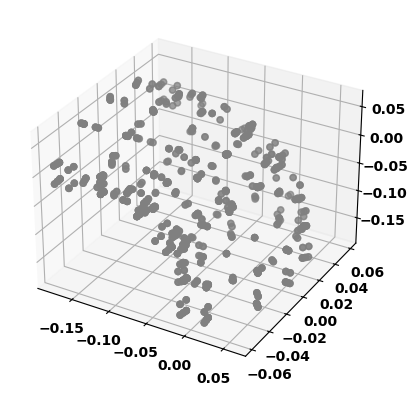

In [10]:
plot_vertices(v_matrix)

<Axes3D: >

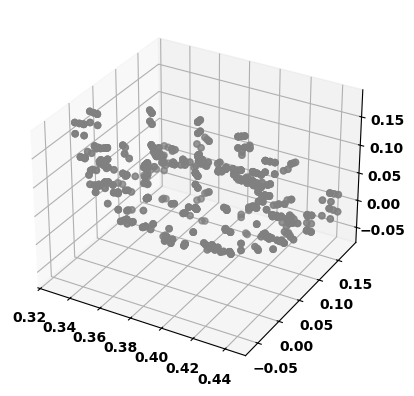

In [11]:
plot_vertices(v_matrix_test)

This confirms that we're dealing with 2 completely separate meshes. To confirm, this is the corresponding orientation we're dealing with.

![Orientation of given widgets](../img/90deg-bend-fitting-samples-comparison-with-plot.png)

Lets get some more stats.

In [12]:
np.mean(v_matrix, axis=0)

array([-6.07087840e-02,  2.46351263e-19, -6.04368173e-02])

In [13]:
np.max(v_matrix, axis=0)

array([0.060638, 0.058571, 0.060638])

In [14]:
np.min(v_matrix, axis=0)

array([-0.179681, -0.058571, -0.179681])

In [15]:
np.mean(v_matrix_test, axis=0)

array([0.38548269, 0.06070876, 0.06043682])

In [16]:
np.max(v_matrix_test, axis=0)

array([0.444054, 0.179681, 0.179681])

In [17]:
np.min(v_matrix_test, axis=0)

array([ 0.326911, -0.060638, -0.060638])

Since our objects are not aligned in space, let's subtract the mean from each one to center them at their centroid.

In [18]:
v_matrix_norm = v_matrix - np.mean(v_matrix, axis=0)
np.mean(v_matrix_norm, axis=0)

array([ 1.57664808e-17,  2.46351263e-19, -2.62774680e-18])

In [19]:
v_matrix_test_norm = v_matrix_test - np.mean(v_matrix_test, axis=0)
np.mean(v_matrix_test_norm, axis=0)

array([2.16789111e-17, 0.00000000e+00, 7.88324041e-18])

Both meshes appear to be centered. What are their extents?

In [20]:
np.max(v_matrix_norm, axis=0)

array([0.12134678, 0.058571  , 0.12107482])

In [21]:
np.max(v_matrix_test_norm, axis=0)

array([0.05857131, 0.11897224, 0.11924418])

At first glance, it looks like the meshes are different, but we note that their orientation is not the same hence their extents will also be different. We know that the mesh is rotated, so we should observe similarities in extents within different axes, and we do see that the X dimension of the first aligns well with the Z dimension of the second, Y aligns with X, and X aligns with Y.

As a final step, lets see what these aligned objects look like in space.

<Axes3D: >

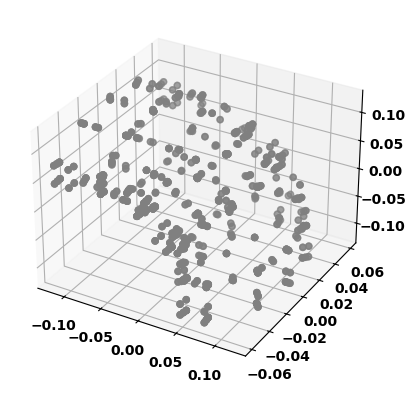

In [22]:
plot_vertices(v_matrix_norm)

<Axes3D: >

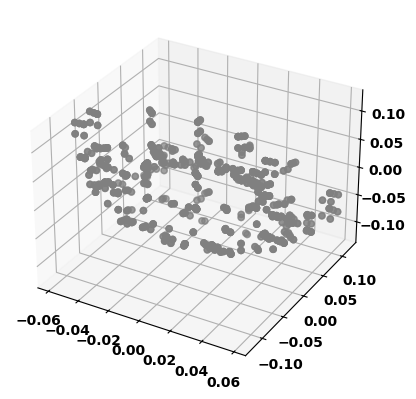

In [23]:
plot_vertices(v_matrix_test_norm)

## Finding the Covariance Matrix

When working with straight pipes, it was relatively easy to estimate the pose from the covariance matrix. The longest eigenvector was usually the one corresponding to the length axis, and the other 2 would have been equal. In the case of the 90 degree bend however, its not as simple. Our object is not symmetric hence estimating its principal components might not be as deterministic.

Let's first see what the covariance matrices look like for each of our shapes.

In [24]:
cov_mat = np.round(np.cov(v_matrix_norm, rowvar=False),4)
cov_mat

array([[ 0.0045,  0.    , -0.0027],
       [ 0.    ,  0.0015, -0.    ],
       [-0.0027, -0.    ,  0.0045]])

In [25]:
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
cov_mat_test

array([[ 0.0015, -0.    ,  0.    ],
       [-0.    ,  0.0045, -0.0027],
       [ 0.    , -0.0027,  0.0045]])

As expected, we see values showing up again across dimensions. In the first example, we see a weak negative relationship between X and Y. This is what our shape looks like in 3D space, when viewed down this plane.

![90 degree bend viewed down -Y axis](../img/90degbend-x-y-plane.png)

This makes sense. As we decrease our values of X, we get smaller corresponding values for Y.

Whereas, in our test shape, we observe a positive relationship between X and Z. Here is the orientation of this object when viewed down this plane.

![90 degree bend viewed down +X axis](../img/90degbend-x-z-planepng.png)

Given the high degree of similarity between our covariance, I'd have expected the orientation to match exactly- just the signs flipped when viewed down this axis. Perhaps we're making a mistake somewhere in the orientation?

Research into the matter yields that the choice of axis is important. We exported this object under default conditions, which means using Y=up and -Z=forward. However, since we exported both meshes under the same orientation, this should not matter. The only difference it would make is when trying to align it back with Blender. As we see, the Z axis in numpy does not necessarily imply Z axis in Blender.

To confirm, we apply a rotation to our sample object along the X axis to give it some sort of alignment and see what the resulting vertex matrix looks like.

In [26]:
ms.load_new_mesh('data/90degbend-sample-1.obj')

m = ms.current_mesh()

v_matrix_test_1 = m.vertex_matrix()
f_matrix_test_1 = m.face_matrix()

<Axes3D: >

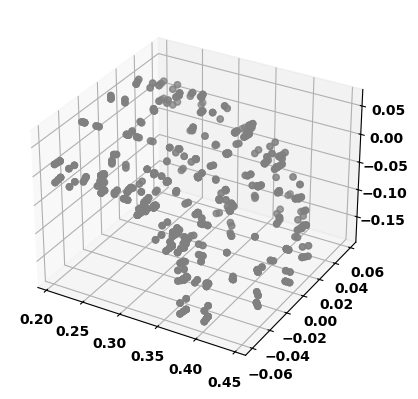

In [27]:
plot_vertices(v_matrix_test_1)

<Axes3D: >

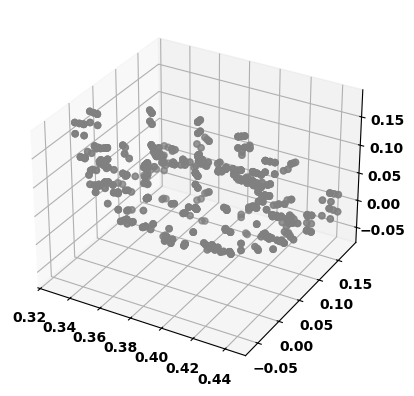

In [28]:
plot_vertices(v_matrix_test)

I think we will come back to this issue later if problems persist. For now, since we can confirm that the coordinate system is the same for each of the exported meshes, regardless of which direction is up and forward, our calculations should align.

## Calculating Eigenvectors

In the straight pipe example, the eigenvectors of the covariance matrix gave us the degree of rotation needed to transform our unit pipe. The logic behind that was, our original unit pipe had a definite direction of maximum covariance (the length axis). If we could find the length axis of the sample pipe (by finding the local direction of highest spread), we could find the rotation amount. This worked well since we knew that simple pipes had one definite axis with larger / different covariance than the rest.

In our 90 degree bend, things are not so straightforward. Or are they? We observe one unique value for covariance in our sample shape.

In [29]:
cov_mat

array([[ 0.0045,  0.    , -0.0027],
       [ 0.    ,  0.0015, -0.    ],
       [-0.0027, -0.    ,  0.0045]])

In [30]:
cov_mat_test

array([[ 0.0015, -0.    ,  0.    ],
       [-0.    ,  0.0045, -0.0027],
       [ 0.    , -0.0027,  0.0045]])

Let's just see what the eigenvectors look like for our test object.

In [31]:
eg_val, eg_vec = np.linalg.eigh(cov_mat_test)
eg_vec

array([[ 1.        , -0.        ,  0.        ],
       [ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678]])

In [32]:
eg_val

array([0.0015, 0.0018, 0.0072])

We know that the eigenvalues give us the directions of maximum covariance. In this case, our 3rd eigenvalue is largest, meaning the Z axis has the largest covariance. We need to align this with our observed covariance in the sample object.

What is the covariance matrix of our sample?

In [33]:
eg_val_org, eg_vec_org = np.linalg.eigh(cov_mat)
eg_vec_org

array([[-1.71189817e-15, -7.07106781e-01, -7.07106781e-01],
       [ 1.00000000e+00, -2.55351296e-15,  1.11022302e-16],
       [-1.55431223e-15, -7.07106781e-01,  7.07106781e-01]])

In [34]:
eg_val_org

array([0.0015, 0.0018, 0.0072])

As a reminder, this is what our original object looked like.

<Axes3D: >

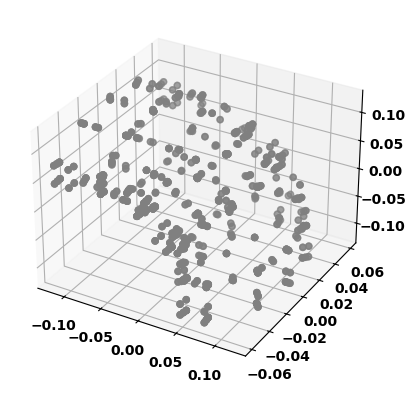

In [35]:
plot_vertices(v_matrix_norm)

And the sample.

<Axes3D: >

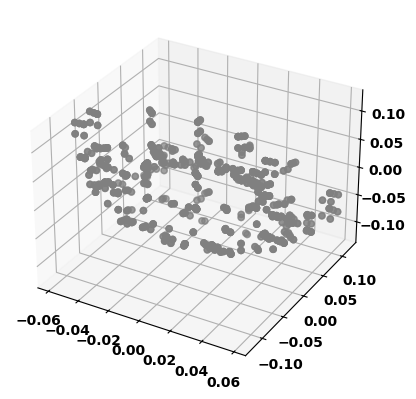

In [36]:
plot_vertices(v_matrix_test_norm)

The original object has the Z variable corresponding to the highest covariance, followed by Y and X. We will need to sort our derived eigenvectors based on this information- the largest one will go in the Z slot, second largest in Y and so on. In this case, its seems like the order is aligned. Hence we can calculate the rotation matrix, by first reordering our eigenvectors.

In [37]:
reorder_eg_vec = eg_vec[:, np.argsort(eg_val)]
reorder_eg_vec

array([[ 1.        , -0.        ,  0.        ],
       [ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678]])

In this case, our sorted eigenvectors are the same.

The rotation matrix is calculated as an identity 4x4 matrix with the `reorder_eg_vec` matrix in the top 3x3 quadrant.

In [38]:
test_rotation_matrix = np.eye(4,4)
test_rotation_matrix[:3, :3] = reorder_eg_vec
test_rotation_matrix

array([[ 1.        , -0.        ,  0.        ,  0.        ],
       [ 0.        , -0.70710678, -0.70710678,  0.        ],
       [ 0.        , -0.70710678,  0.70710678,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  1.        ]])

Now theoretically, if we multiply this matrix by our original vertices, we should get the correct orientation? Lets see.

Original Shape.

<Axes3D: >

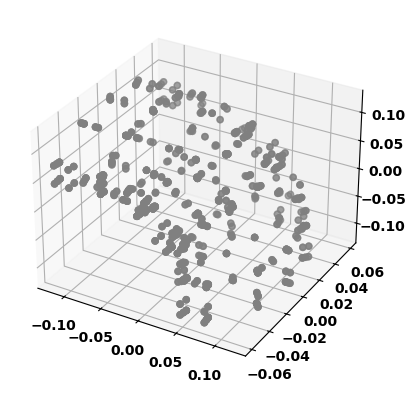

In [39]:
plot_vertices(v_matrix_norm)

Sample Shape.

<Axes3D: >

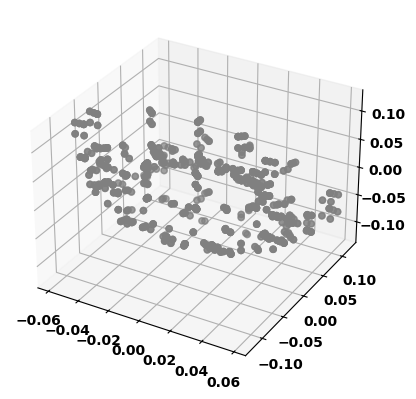

In [40]:
plot_vertices(v_matrix_test_norm)

Transformed vertices.

<Axes3D: >

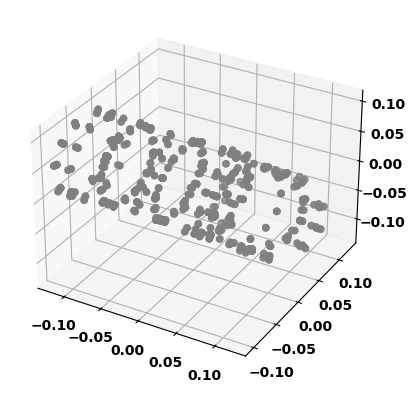

In [41]:
v_matrix_transformed = test_rotation_matrix @ np.transpose(np.c_[v_matrix_norm, np.ones(v_matrix_norm.shape[0])])
plot_vertices(np.transpose(v_matrix_transformed)[:, :3])

That does not look quite right.

## Attempt 2

To start off with, lets add some axis labels on our vertex chart so we can get our bearings. We redefine our `plot_vertices` function from earlier. We also add the ability to shade the vertices by their depth- in this case the Y value, so we can see which ones are closer to the front than others.

In [42]:
def plot_vertices(vertices):
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    
    ax.scatter(vertices[:,0], vertices[:,1], vertices[:,2], c=vertices[:,1], cmap='grey')

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')

    return ax

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

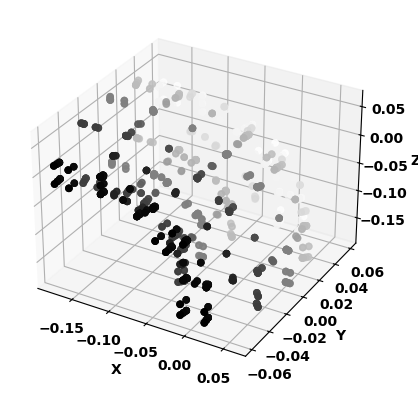

In [43]:
plot_vertices(v_matrix)

Another tweak I'd like to make is to ensure absolutely proper alignment between our Blender exported mesh and the numpy loaded mesh. This relates to the forward, up direction confusion we had from earlier. We orient our sample object like so.

![New Sample 90 Deg Bend for Testing](../img/new-sample-pipe.png)

This new object is constrained to the positive quadrant (yes there is a litte that goes negative, but mostly). We want to export this best such that its orientation lines up with what we see in matplotlib and numpy. Our first option is the Blender default: Forward Axis -Z, Up Axis Y.

This is what the object looks like in matplotlib 3d space.

In [44]:
ms.load_new_mesh('data/90degbend-orig-2.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
v_matrix

array([[ 0.025456,  0.      ,  0.015556],
       [ 0.025456,  0.      ,  0.015556],
       [ 0.025456,  0.      ,  0.015556],
       ...,
       [ 0.014947,  0.055782, -0.121681],
       [ 0.014947,  0.055782, -0.121681],
       [ 0.014947,  0.055782, -0.121681]], shape=(1352, 3))

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

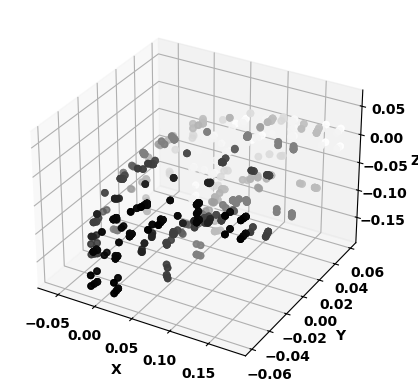

In [45]:
plot_vertices(v_matrix)

Something does not seem quite right- the shape seems off. Let's try another export method. Here, we try Forward= -Y, Up= Z.

In [46]:
ms.load_new_mesh('data/90degbend-orig-3.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
v_matrix

array([[-0.025456,  0.015556,  0.      ],
       [-0.025456,  0.015556,  0.      ],
       [-0.025456,  0.015556,  0.      ],
       ...,
       [-0.014947, -0.121681,  0.055782],
       [-0.014947, -0.121681,  0.055782],
       [-0.014947, -0.121681,  0.055782]], shape=(1352, 3))

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

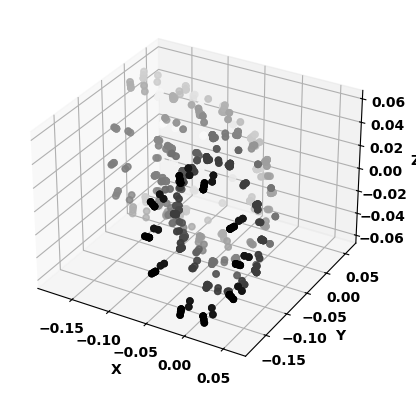

In [47]:
plot_vertices(v_matrix)

Seems like the X and Y directions might have been flipped. Let's try one more export- Forward Axis= Y, Up=Z

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

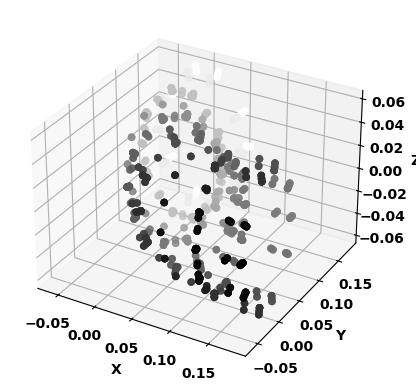

In [48]:
ms.load_new_mesh('data/90degbend-orig-4.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
plot_vertices(v_matrix)

Now we see some alignment. As a reminder, this is what our object looks like in the Blender viewport.

![90 Degree Bend Sample 4](../img/90degbend-sample-4.png)

Let's also export our test mesh using the same export settings. As a reminder, choosing the export settings will not matter as long as we're consistent, since the eigen transforms will work regardless. We are going through this process since I'd like to be able to adequately verify what axes are being rotated and why.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

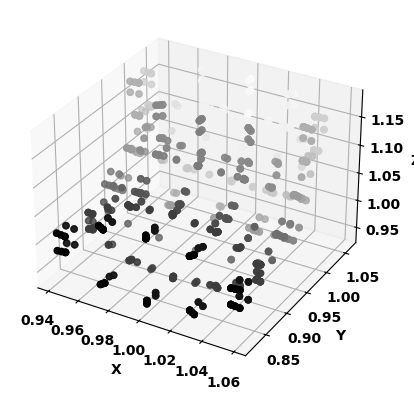

In [49]:
ms.load_new_mesh('data/90degbend-test-4.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
plot_vertices(v_matrix_test)

![90 Degree Bend test object 4](../img/90degbend-test-object.png)

As a side, we have also given this object translation values of (1,1,1), so our vertices will definitely need to be centered before we do anything. Let's do that now.

In [50]:
v_matrix_norm = v_matrix - np.mean(v_matrix, axis=0)
v_matrix_norm

array([[-3.49808129e-02, -7.62647885e-02, -2.46351263e-19],
       [-3.49808129e-02, -7.62647885e-02, -2.46351263e-19],
       [-3.49808129e-02, -7.62647885e-02, -2.46351263e-19],
       ...,
       [-4.54898129e-02,  6.09722115e-02,  5.57820000e-02],
       [-4.54898129e-02,  6.09722115e-02,  5.57820000e-02],
       [-4.54898129e-02,  6.09722115e-02,  5.57820000e-02]],
      shape=(1352, 3))

In [51]:
v_matrix_test_norm = v_matrix_test - np.mean(v_matrix_test, axis=0)
v_matrix_test_norm

array([[ 1.73076923e-07, -6.02441930e-02, -1.15708774e-01],
       [ 1.73076923e-07, -6.02441930e-02, -1.15708774e-01],
       [ 1.73076923e-07, -6.02441930e-02, -1.15708774e-01],
       ...,
       [ 2.88751731e-02,  1.04238070e-02,  6.09722256e-02],
       [ 2.88751731e-02,  1.04238070e-02,  6.09722256e-02],
       [ 2.88751731e-02,  1.04238070e-02,  6.09722256e-02]],
      shape=(1352, 3))

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

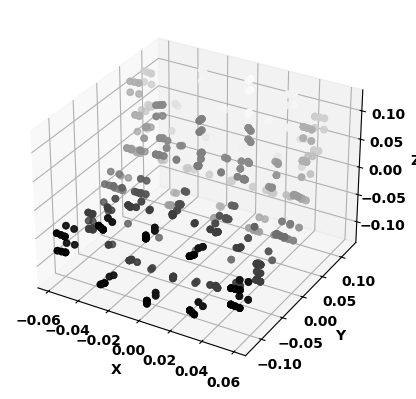

In [52]:
plot_vertices(v_matrix_test_norm)

Now lets compare the covariance matrices of these 2 arrays.

In [53]:
cov_mat = np.round(np.cov(v_matrix, rowvar=False), 4)
cov_mat

array([[ 0.0045, -0.0027,  0.    ],
       [-0.0027,  0.0045, -0.    ],
       [ 0.    , -0.    ,  0.0015]])

In [54]:
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False), 4)
cov_mat_test

array([[ 0.0015, -0.    , -0.    ],
       [-0.    ,  0.0045,  0.0027],
       [-0.    ,  0.0027,  0.0045]])

Similar results to earlier, but this time we should be able to definitively say why the covariance numbers are what they are. In the first example, we observe a weak negative relationship between X and Y. This aligns with our observed vertex orientation. With an increase in X (red axis), we observe a decrease in Y (green axis).

![Sample Object- Vertex Orientation](../img/covariance-analysis-orig-x-y.png)

Likewise, in our second covariance matrix, we observe a weak positive relationship between Y and Z. This too aligns with our observations. We center the mesh at the origin, and look down the +X axis.= at the Y-Z plane.

![Test Object- Vertex Orientation](../img/covariance-analysis-test-y-z.png)

Here too, it makes sense why the covariance is positive. An increase in Y (green axis) is associated with an increase in Z (blue axis). 

Good. We can now ensure axis alignment across Blender and Matplotlib.

The next step is to find the eigenvectors of both our objects' covariance matrices. This will give us the axes along with we have maximum spread. Theoretically speaking, for our sample object, I would expect this to be the unit vectors for +X and +Y- we've already confirmed that the object is oriented to both these axes in Blender, and covariance values did not vary too much across other axes. Lets see.

In [55]:
eg_val, eg_vec = np.linalg.eigh(cov_mat)
eg_vec

array([[ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678],
       [ 1.        , -0.        ,  0.        ]])

In [56]:
eg_val

array([0.0015, 0.0018, 0.0072])

An interesting observation. The number 0.7071 also aligns with a known function - sin or cosine of 45 degrees. This implies that our eigenvectors, or axes of maximum variance are the unit vectors below, along with the positive Z axis.

![Eigen decomposition of the sample object](../img/eigenvector-decomp-sample.png)

From the eigenvalues, we can tell that the direction X=-0.7071, Y=0.7071, Z=0 has the highest observed variance. This corresponds with the blue vector in the image above.

We can also decompose our test object in a similar fashion to get its associated eigenvectors and values.

In [57]:
eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
eg_vec_test

array([[ 1.        ,  0.        ,  0.        ],
       [ 0.        , -0.70710678,  0.70710678],
       [ 0.        ,  0.70710678,  0.70710678]])

In [58]:
eg_val_test

array([0.0015, 0.0018, 0.0072])

Here, we see the unit X vector is the direction of least covariance. The direction of highest covariance is the unit vector X=0, Y=0.7071, Z=0.7071 which, overlayed on our test object looks like the green vector in the image below.

![Eigen decomposition of the test object](../img/eigenvector-decomp-test.png)

Things are starting to make some sense here. However, I see one issue that could pop up to ruin the party. In our sample, the second largest eigenvector pointed away from the object while in our test object this same eigenvector points into it. This is mathematically sound, the vectors are simply scalar multiples of each other, and completely orthogonal- but it would mean that our objects are completely incorrectly rotated in space. Our other 2 eigenvectors will not affect the final output as much, since the object is symmetric in these directions about the centroid.

What's worse, I'm not certain if our eigenvector decomposition is guaranteed to find these exact vectors every time. Since both are valid orthogonal vectors, our algorithm could return either one.

We need a test with an error metric to see whether the vector returned is adequate, or if we need to choose the diametrically opposite one.

An idea inspired by Gemini is to project all the vertices onto our problematic axis and find the mean. We observe that every single point in our object lies entirely above or below our centroid. We do this projection with both our sample object and test object. If the means' signs are aligned, then we have chosen the correct vector. If not, swap it around. Let's see how we might be able to solve this.

We have previously calculated projections by using the @ operator, or dot product.

In [59]:
# projected_v = np.dot(v_matrix_norm, eg_vec[:,1])
projected_v = v_matrix_norm @ eg_vec[:, 1]
np.mean(projected_v)

np.float64(-7.39053788581835e-18)

In [60]:
projected_v_test = v_matrix_test_norm @ eg_vec_test[:, 1]
np.mean(projected_v_test)

np.float64(1.372997705009809e-16)

While the signs are indeed different, I'm not confident in the process since the numbers are so small. Seems like the centroid we've been using in our calculations is different from the centroid in Blender. Our centroid is actually within the shape, not like the one suggested by Blender. Hence, we do get a spread of some positive and some negative numbers when we calculate the mean of the projected points.

A theory I'd like to test out is as follows. Since the pipe bends towards the center, the magnitude of the projected points should be asymmetric- there will be a larger magnitude in one direction of our eigenvector. Lets see on our test object.

In [61]:
np.max(v_matrix_test_norm @ eg_vec_test[:, 1])

np.float64(0.08426762535007683)

In [62]:
np.min(v_matrix_test_norm @ eg_vec_test[:, 1])

np.float64(-0.08430026732376544)

Wow that looks almost exactly the same. What about the sample object? I'd expect this to be same too.

In [63]:
np.max(v_matrix_norm @ eg_vec[:, 1])

np.float64(0.08430028144498089)

In [64]:
np.min(v_matrix_norm @ eg_vec[:, 1])

np.float64(-0.08426831833564255)

Yup. No luck.

## Attempt 3

The goal with todays attempt will be to discretely identify features on the object that will help identify the pose of the object. Let's take a look at our sample object once again in Blender.

![90 Degree Bend Sample 4](../img/90degbend-sample-4.png)

The centroid of this object, while small, is not the same as the origin, as we have found.

In [65]:
np.mean(v_matrix, axis=0)

array([6.04368129e-02, 6.07087885e-02, 2.46351263e-19])

We got thrown off by the exponents. Rounded to 2 decimals, this is what we see.

In [66]:
np.round(np.mean(v_matrix, axis=0),2)

array([0.06, 0.06, 0.  ])

If we apply this translation onto our shape, we see that the centroid (and thus the centered shape) looks like this.

![90 Degree bend centered vertices](../img/centered-sample-90degbend.png)

This changes the outlook quite a bit. Our centorid is well within the bounds of the shape- in fact its closer to the inside edge than it is the outside. Our eigenvector decomposition now looks like this.

![90 Degree bend centered vertices with eigenvectors](../img/centered-sample-90degbend-egvec.png)

Projecting the points onto the axis looks like this.

![90 Degree bend centered vertices with projected points](../img/centered-sample-90degbend-project.png)

While the lines may not necessarily be exactly 90 degrees, we do see that our max and min values are fairly similar- explaining why our earlier implementation did not work.

One more attempt I'd like to make before moving onto algorithmic or machine learning methods is as follows. Currently, we see that our projected points have the same extent on our eigenvector. If we instead create a buffer zone on either side of our eigenvector, the extents will become skewed on one side.

![90 Degree bend with buffer and projected points](../img/centered-sample-90degbend-project-buffer.png)

In the schematic above, we create a buffer zone extending out from our eigenvector. Vertices within this zone will be discarded from the projection calculation. As a result, the bulk of the bend's apex will fall in this zone, and our extents will be skewed to one side- namely the one containing the end of the bend. In the graphic above, we discard the extreme right projected point which lies within our red buffer zone, and introduce a little skew into our max and min calculations.

Now, how would we go about doing this? We will need to first project our points onto the blue eigenvector and discard them if they lie within a certain buffer. The choice of buffer here is critical too since too small and the skew may not show up- too large and we may also include our other extreme projected point within the buffer, defeating its purpose.

To start out with, lets discard points that are within 25% of the max extent in the blue eigenvector's direction.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

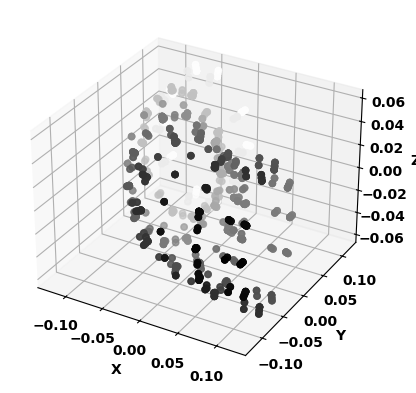

In [67]:
plot_vertices(v_matrix_norm)

In [68]:
projected_v = v_matrix_norm @ eg_vec[:, 2]
np.min(projected_v, axis=0)

np.float64(-0.17012280322640833)

In [69]:
max_extent = np.max(projected_v, axis=0)
max_extent

np.float64(0.1697388787627503)

As expected the extents of our projected points are the same. Let's work on discarding those points that are within 25% of the max extent of the shape.

In [70]:
v_matrix_norm_buffer = np.where(( abs(projected_v[:,None]) > max_extent*0.25 ), v_matrix_norm, 0 )
v_matrix_norm_buffer

array([[ 0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ],
       ...,
       [-0.04548981,  0.06097221,  0.055782  ],
       [-0.04548981,  0.06097221,  0.055782  ],
       [-0.04548981,  0.06097221,  0.055782  ]], shape=(1352, 3))

OK, we have set the coordinates of the vertices within our buffer zone. If we plot these, this is what we see.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

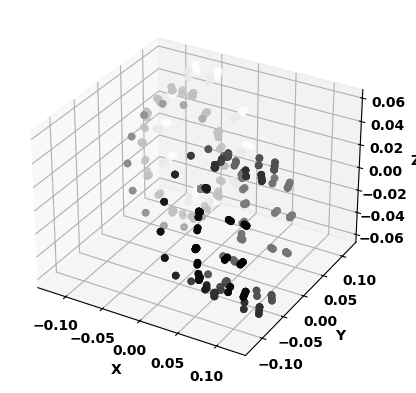

In [71]:
plot_vertices(v_matrix_norm_buffer)

Looks almost the same... what if we increase the threshold?

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

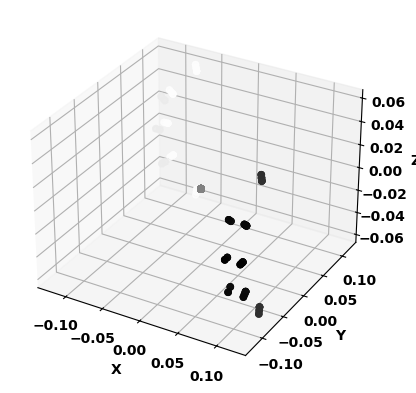

In [72]:
v_matrix_norm_buffer_test = np.where(( abs(projected_v[:,None]) > max_extent*0.75 ), v_matrix_norm, 0 )
plot_vertices(v_matrix_norm_buffer_test)

OK Looks good. Switch back to the 0.25 threshold. Now we should have a skew in our projected vertices onto the other eigenvector.

In [73]:
projected_v_2 = v_matrix_norm_buffer @ eg_vec[:, 1]
np.min(projected_v_2)

np.float64(-0.08426831833564255)

In [74]:
np.max(projected_v_2)

np.float64(0.06841159207171915)

And finally, we do actually have a skew. This should be able to definitively tell us if our eigenvector is pointed in the right direction.

I scribbled this theorem down on a piece of paper in a hospital waiting room-

"After projecting our vertices onto our eigenvector, if the magnitude of largest positive number is greater than the magnitude of the smallest negative number, our eigenvector is pointed towards the center of the circle. If the magnitude of the largest positive number is less than the magnitude of the smallest negative number, then our eigenvector is pointed outward."

![Eigenvector direction calculation](../img/eg_vec-direction-calculation.png)

Since we have this skew introduced, we can say that our extents should be different. If we project our buffered points onto the given eigenvector (with no idea where it should be pointing), we calculate the largest positive value (points that are in the direction of our eigenvector) and largest negative value (points that are in the opposite direction of our eigenvector).

If the magnitude of the largest positive value is greater than the smallest negative, the eigenvector points inwards.
Likewise, if the magnitude of the smallest negative is greater than the largest positive, the eigenvector points outwards.

I hope this makes sense. It does to me.

So now we have a method to see which way our eigenvector is pointing. Let's move back to estimating the pose of our object. Currently we've been testing with the sample object. And to clarify, our correctly oriented eigenvectors are as follows.

In [75]:
np.abs(np.max(projected_v_2)) > np.abs(np.min(projected_v_2))

np.False_

Our minimum is greater than the maximum. Therefore the current eigenvector is pointed outward. We shall use this as the basis going forward.

However, we still need to rotate our sample shape. Currently, the eigenvectors do not align with our world basis. Let's create our required covariance matrix and multiply it by our points.

In [76]:
eg_vec

array([[ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678],
       [ 1.        , -0.        ,  0.        ]])

In [77]:
eg_val

array([0.0015, 0.0018, 0.0072])

In [78]:
np.argsort(eg_val, descending=True)

array([2, 1, 0])

In [79]:
cov_mat = eg_vec[:, np.argsort(eg_val, descending=False)]
cov_mat

array([[ 0.        , -0.70710678, -0.70710678],
       [ 0.        , -0.70710678,  0.70710678],
       [ 1.        , -0.        ,  0.        ]])

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

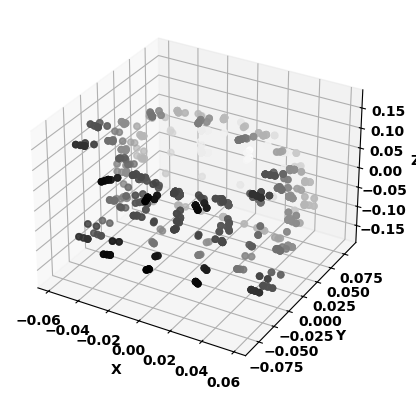

In [80]:
unit_bend = v_matrix_norm @ cov_mat
plot_vertices(unit_bend)

The `unit_bend` object stores our sample unit 90 deg object.

To confirm, we should expect the eigenvector decomposition of the unit bend to be our i, j, k basis vectors.

In [81]:
cov_mat_basis = np.round(np.cov(unit_bend, rowvar=False), 4)
eg_val, eg_vec = np.linalg.eigh(cov_mat_basis)
eg_vec

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [82]:
eg_val

array([0.0015, 0.0018, 0.0072])

Looks to be correct. This is the neutral orientation of our shape.

Now, onto our test object.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

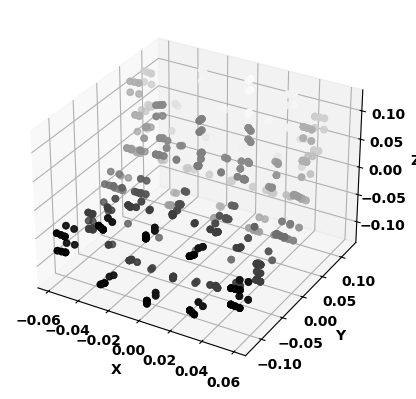

In [83]:
plot_vertices(v_matrix_test_norm)

Calculating the covariance matrix -->

In [84]:
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
cov_mat_test

array([[ 0.0015, -0.    , -0.    ],
       [-0.    ,  0.0045,  0.0027],
       [-0.    ,  0.0027,  0.0045]])

Conducting the eigenvector decomposition on this -->

In [85]:
eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
eg_vec_test

array([[ 1.        ,  0.        ,  0.        ],
       [ 0.        , -0.70710678,  0.70710678],
       [ 0.        ,  0.70710678,  0.70710678]])

In [86]:
eg_val_test

array([0.0015, 0.0018, 0.0072])

Finding the correct eigenvector orientation -->

1) project onto largest eg_vec

In [87]:
proj_largest = v_matrix_test_norm @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[0]]

2) find the extents

In [88]:
max_extent = abs(np.max(proj_largest))
max_extent

min_extent = abs(np.min(proj_largest))
min_extent

print(f"Max extent: {max_extent}, Min extent: {min_extent}")

Max extent: 0.16973817740905686, Min extent: 0.17012350458010173


3) find buffered vertices

In [89]:
v_matrix_test_norm_buffer = np.where( proj_largest[:, None] > max_extent * 0.25, v_matrix_test_norm, 0)
v_matrix_test_norm_buffer

array([[0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        ],
       ...,
       [0.02887517, 0.01042381, 0.06097223],
       [0.02887517, 0.01042381, 0.06097223],
       [0.02887517, 0.01042381, 0.06097223]], shape=(1352, 3))

4) project buffered vertices onto second eigenvector

In [90]:
proj_second = v_matrix_test_norm_buffer @ eg_vec_test[:, np.argsort(eg_val_test, descending=False)[1]]

5) test if min extent > max extent; if not swap the direction of the eigenvector

In [91]:
np.min(proj_second)

np.float64(-0.06841157795050372)

In [92]:
np.max(proj_second)

np.float64(0.08426762535007683)

In [93]:
if abs(np.min(proj_second)) > abs(np.max(proj_second)):
    swap = 1        # correct orientation
else:
    swap = -1       # incorrect orientation

print(swap)

-1


Creating the rotation matrix -->

In [94]:
rot_matrix = eg_vec_test[:, np.argsort(eg_val_test, descending=False)]
rot_matrix

array([[ 1.        ,  0.        ,  0.        ],
       [ 0.        , -0.70710678,  0.70710678],
       [ 0.        ,  0.70710678,  0.70710678]])

Add the swap direction, if needed.

In [95]:
rot_matrix[:, 1] = rot_matrix[:, 1] * swap

# also need to swap the third eg vec to maintain right hand rule
rot_matrix[:, 0] = rot_matrix[:, 0] * swap
rot_matrix

array([[-1.        , -0.        ,  0.        ],
       [-0.        ,  0.70710678,  0.70710678],
       [-0.        , -0.70710678,  0.70710678]])

Now, multiply our basis unit shape by this rotation matrix -->

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

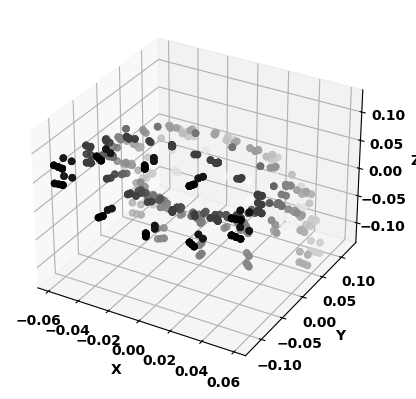

In [96]:
test_config = unit_bend @ rot_matrix
plot_vertices(test_config)

Something is not quite lining up- but I'm confident enough in this technique to give it another go.

Let's do this methodically.

## Attempt 4

We start with 2 objects- one sample and one test. The sample contains the vertices of our unit bend, while `test` serves as a test object to measure success against. 

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

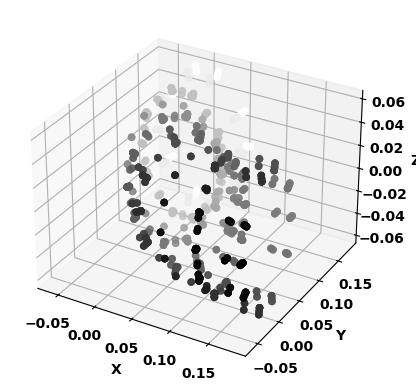

In [97]:
ms.load_new_mesh('data/90degbend-orig-4.obj')

m = ms.current_mesh()

v_matrix = m.vertex_matrix()
f_matrix = m.face_matrix()
plot_vertices(v_matrix)

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

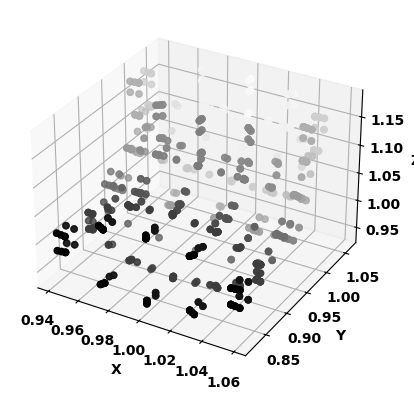

In [98]:
ms.load_new_mesh('data/90degbend-test-4.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
f_matrix_test = m.face_matrix()
plot_vertices(v_matrix_test)

Neither of these objects are normalized to the centroid. Therefore we must subtract the mean from each of them.

[6.04368129e-02 6.07087885e-02 2.46351263e-19]


<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

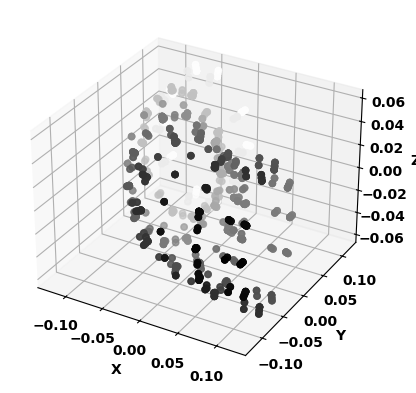

In [99]:
v_matrix_norm = v_matrix - np.mean(v_matrix, axis=0)
print(np.mean(v_matrix, axis=0))
plot_vertices(v_matrix_norm)

[0.99999983 0.93956319 1.06070877]


<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

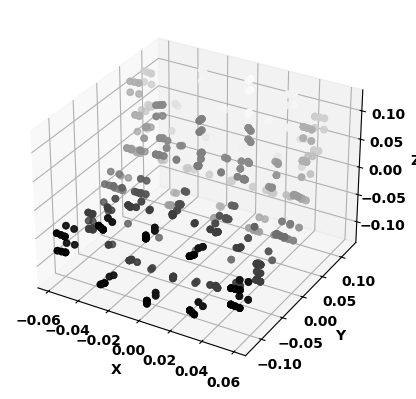

In [100]:
v_matrix_test_norm = v_matrix_test - np.mean(v_matrix_test, axis=0)
print(np.mean(v_matrix_test, axis=0))
plot_vertices(v_matrix_test_norm)

Our unit bend, while normalized, does not decompose down to the current basis vector i,j,k. We must find its neutral orientation, and do so with a similar method to above.

cov_mat = 
[[ 0.0045 -0.0027  0.    ]
 [-0.0027  0.0045 -0.    ]
 [ 0.     -0.      0.0015]]

eg_vec = 
[[ 0.         -0.70710678 -0.70710678]
 [ 0.         -0.70710678  0.70710678]
 [ 1.         -0.          0.        ]]

eg_val = [0.0015 0.0018 0.0072]

primary axis max_extent = 0.17
primary axis min_extent = 0.17

secondary axis skewed max_extent = 0.07
secondary axis skewed min_extent = 0.08

min > max, eg_vec points outward already

rot_matrix = 
[[-0.70710678 -0.70710678  0.        ]
 [ 0.70710678 -0.70710678  0.        ]
 [ 0.         -0.          1.        ]]

test cov_mat = [[ 0.0072  0.     -0.    ]
 [ 0.      0.0018  0.    ]
 [-0.      0.      0.0015]]

basis eg_vec = 
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


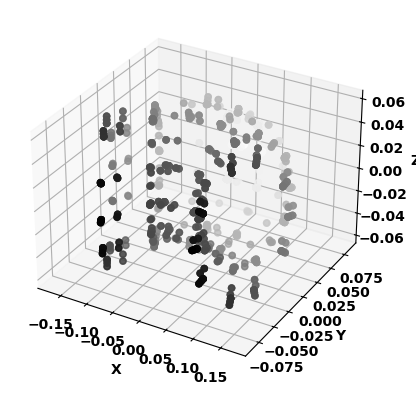

In [101]:
# 1) Find covariance matrix
cov_mat = np.round(np.cov(v_matrix_norm, rowvar=False),4)
print(f"cov_mat = \n{cov_mat}\n")

# 2) Eigen decomposition
eg_val_basis, eg_vec_basis = np.linalg.eigh(cov_mat)
print(f"eg_vec = \n{eg_vec_basis}\n")
print(f"eg_val = {eg_val_basis}\n")

# 3) Find the correct orientation of 2nd eigenvector
## a) Project all points onto largest eg_vec
proj_basis = v_matrix_norm @ eg_vec_basis[:, np.argsort(eg_val_basis, descending=True)[0]]

## b) Calculate extents of proj_basis
proj_max = np.round(np.max(proj_basis),2)
proj_min = abs(np.round(np.min(proj_basis),2))
print(f"primary axis max_extent = {proj_max}")
print(f"primary axis min_extent = {proj_min}\n")

## c) Nullify vertices that lie within 25% of the max extent
skew_basis = np.where( abs(proj_basis[:, None]) > proj_max * 0.25, v_matrix_norm, 0 )

## d) Project skewed vertices onto 2nd largest eg_vec
proj_basis_skew = skew_basis @ eg_vec_basis[:, np.argsort(eg_val_basis, descending=True)[1]]

## e) Determine if max_extent > min_extent and vice versa
skew_max = np.round(np.max(proj_basis_skew),2)
skew_min = abs(np.round(np.min(proj_basis_skew),2))
print(f"secondary axis skewed max_extent = {skew_max}")
print(f"secondary axis skewed min_extent = {skew_min}\n")

## f) Calculate necessary swap factor
if skew_min > skew_max:
    swap = 1
    print("min > max, eg_vec points outward already\n")
else:
    swap = -1
    print("max > min, eg_vec points inward, swap necessary\n")

# 4) Calculate the rotation matrix
rot_matrix_basis = eg_vec_basis[:, np.argsort(eg_val_basis, descending=True)]
rot_matrix_basis[:, 1] = rot_matrix_basis[:, 1] * swap
rot_matrix_basis[:, 2] = rot_matrix_basis[:, 2] * swap
print(f"rot_matrix = \n{rot_matrix_basis}\n")

# 5) Multiply input vertices by rotation matrix
unit_basis = v_matrix_norm @ rot_matrix_basis
plot_vertices(unit_basis)

# 6) Confirm eigen decomposition of unit_basis is the i,j,k unit vectors
test_cov_mat = np.round(np.cov(unit_basis, rowvar=False),4)
print(f"test cov_mat = {test_cov_mat}\n")
eg_val_test, eg_vec_test = np.linalg.eigh(test_cov_mat)
print(f"basis eg_vec = \n{np.round(eg_vec_test[:, np.argsort(eg_val_test, descending=True)],2)}")

Our decomposition yields the basis unit vectors (albeit one points in the negative direction). However, the orientation of our shape in the graph aligns with what we expect. Its important to note that our direction for the second eigenvector axis (in this case, the Y axis) is pointed outward from the center of the bend. The direction of the largest axis is X.

That logic seemed sound to me. And now, we proceed to do the same with our test object.

cov_mat = 
[[ 0.0015 -0.     -0.    ]
 [-0.      0.0045  0.0027]
 [-0.      0.0027  0.0045]]

eg_vec = 
[[ 1.          0.          0.        ]
 [ 0.         -0.70710678  0.70710678]
 [ 0.          0.70710678  0.70710678]]

eg_val = [0.0015 0.0018 0.0072]

primary axis max_extent = 0.17
primary axis min_extent = 0.17

secondary axis skewed max_extent = 0.08
secondary axis skewed min_extent = 0.07

max > min, eg_vec points inward, swap necessary

rot_matrix = 
[[ 0.         -0.         -1.        ]
 [ 0.70710678  0.70710678 -0.        ]
 [ 0.70710678 -0.70710678 -0.        ]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

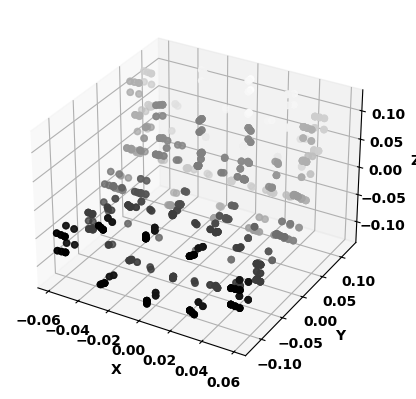

In [102]:
# 1) Find covariance matrix
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
print(f"cov_mat = \n{cov_mat_test}\n")

# 2) Eigen decomposition
eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
print(f"eg_vec = \n{eg_vec_test}\n")
print(f"eg_val = {eg_val_test}\n")

# 3) Find the correct orientation of 2nd eigenvector
## a) Project all points onto largest eg_vec
proj_test = v_matrix_test_norm @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[0]]

## b) Calculate extents of proj_test
proj_max = np.round(np.max(proj_test),2)
proj_min = abs(np.round(np.min(proj_test),2))
print(f"primary axis max_extent = {proj_max}")
print(f"primary axis min_extent = {proj_min}\n")

## c) Nullify vertices that lie within 25% of the max extent
skew_test = np.where( abs(proj_test[:, None]) > proj_max * 0.25, v_matrix_test_norm, 0 )

## d) Project skewed vertices onto 2nd largest eg_vec
proj_test_skew = skew_test @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[1]]

## e) Determine if max_extent > min_extent and vice versa
skew_max = np.round(np.max(proj_test_skew),2)
skew_min = abs(np.round(np.min(proj_test_skew),2))
print(f"secondary axis skewed max_extent = {skew_max}")
print(f"secondary axis skewed min_extent = {skew_min}\n")

## f) Calculate necessary swap factor
if skew_min > skew_max:
    swap = 1
    print("min > max, eg_vec points outward already\n")
else:
    swap = -1
    print("max > min, eg_vec points inward, swap necessary\n")

# 4) Calculate the rotation matrix
rot_matrix_test = eg_vec_test[:, np.argsort(eg_val_test, descending=True)]
rot_matrix_test[:, 1] = rot_matrix_test[:, 1] * swap
rot_matrix_test[:, 2] = rot_matrix_test[:, 2] * swap
print(f"rot_matrix = \n{rot_matrix_test}\n")

# 5) Multiply input vertices by rotation matrix
transformed_shape = unit_basis @ np.transpose(rot_matrix_test)
plot_vertices(transformed_shape)

Lets test what this object looks like in blender

In [103]:
# ms = pymeshlab.MeshSet()

# m = pymeshlab.Mesh(vertex_matrix=unit_basis, face_matrix=f_matrix)
# ms.add_mesh(m)
# ms.save_current_mesh("unit-basis.obj")

# mt = pymeshlab.Mesh(vertex_matrix=transformed_shape, face_matrix=f_matrix)
# ms.add_mesh(mt)
# ms.save_current_mesh("transformed-shape.obj")


# mtest = pymeshlab.Mesh(vertex_matrix=v_matrix_test_norm, face_matrix=f_matrix_test)
# ms.add_mesh(mtest)
# ms.save_current_mesh("test-object.obj")

![First pass results](../img/first-pass-results.png)

The intent is clear, seems like we just messed up the axes slightly. I do see in our transformed shape, we have a 90 degree rotation and a 45 degree rotation, but the axes along which they need to occur seems wrong. We need the following to accurately capture the orientation of our test object -->

1) 90 degree rotation about up axis
2) 45 degree rotation about red axis

We are actually applying -->

1) 90 degree rotation about up axis
2) 45 degree rotation about green axis 

It seems that we needed to apply the transpose of the derived rotation matrix to get our vertices correctly ordered... Not too sure why that is, but it might have something to do with the dimensionality of the shape. Since our pipe in the eariler example was symmetric about all our axes, it likely did not show up. Let's confirm that this works for other shape examples too.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

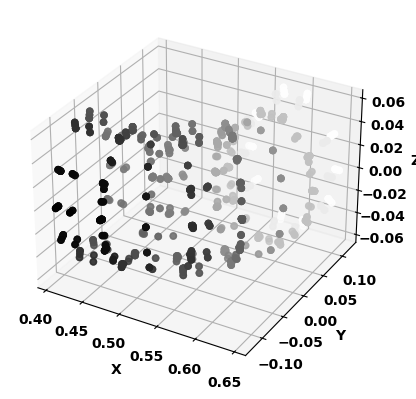

In [104]:
ms.load_new_mesh('data/90degbend-test-object-2.obj')

m = ms.current_mesh()

v_matrix_test_2 = m.vertex_matrix()
plot_vertices(v_matrix_test_2)

Lets see how our algorithm functions on the above test object.

cov_mat = 
[[0.0045 0.0027 0.    ]
 [0.0027 0.0045 0.    ]
 [0.     0.     0.0015]]

eg_vec = 
[[ 0.         -0.70710678  0.70710678]
 [ 0.          0.70710678  0.70710678]
 [ 1.          0.          0.        ]]

eg_val = [0.0015 0.0018 0.0072]

primary axis max_extent = 0.17
primary axis min_extent = 0.17

secondary axis skewed max_extent = 0.08
secondary axis skewed min_extent = 0.07

max > min, eg_vec points inward, swap necessary

rot_matrix = 
[[ 0.70710678  0.70710678 -0.        ]
 [ 0.70710678 -0.70710678 -0.        ]
 [ 0.         -0.         -1.        ]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

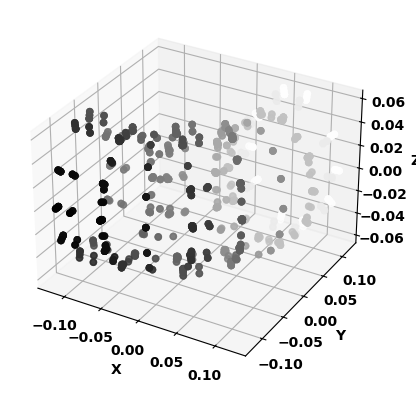

In [105]:
# 0) Center the Vertices
v_matrix_test_norm = v_matrix_test_2 - np.mean(v_matrix_test_2, axis=0)

# 1) Find covariance matrix
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
print(f"cov_mat = \n{cov_mat_test}\n")

# 2) Eigen decomposition
eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
print(f"eg_vec = \n{eg_vec_test}\n")
print(f"eg_val = {eg_val_test}\n")

# 3) Find the correct orientation of 2nd eigenvector
## a) Project all points onto largest eg_vec
proj_test = v_matrix_test_norm @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[0]]

## b) Calculate extents of proj_test
proj_max = np.round(np.max(proj_test),2)
proj_min = abs(np.round(np.min(proj_test),2))
print(f"primary axis max_extent = {proj_max}")
print(f"primary axis min_extent = {proj_min}\n")

## c) Nullify vertices that lie within 25% of the max extent
skew_test = np.where( abs(proj_test[:, None]) > proj_max * 0.25, v_matrix_test_norm, 0 )

## d) Project skewed vertices onto 2nd largest eg_vec
proj_test_skew = skew_test @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[1]]

## e) Determine if max_extent > min_extent and vice versa
skew_max = np.round(np.max(proj_test_skew),2)
skew_min = abs(np.round(np.min(proj_test_skew),2))
print(f"secondary axis skewed max_extent = {skew_max}")
print(f"secondary axis skewed min_extent = {skew_min}\n")

## f) Calculate necessary swap factor
if skew_min > skew_max:
    swap = 1
    print("min > max, eg_vec points outward already\n")
else:
    swap = -1
    print("max > min, eg_vec points inward, swap necessary\n")

# 4) Calculate the rotation matrix
rot_matrix_test = eg_vec_test[:, np.argsort(eg_val_test, descending=True)]
rot_matrix_test[:, 1] = rot_matrix_test[:, 1] * swap
rot_matrix_test[:, 2] = rot_matrix_test[:, 2] * swap
print(f"rot_matrix = \n{rot_matrix_test}\n")

# 5) Multiply input vertices by rotation matrix
transformed_shape = unit_basis @ np.transpose(rot_matrix_test)
plot_vertices(transformed_shape)

That seemed to work well...

Lets try another one.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

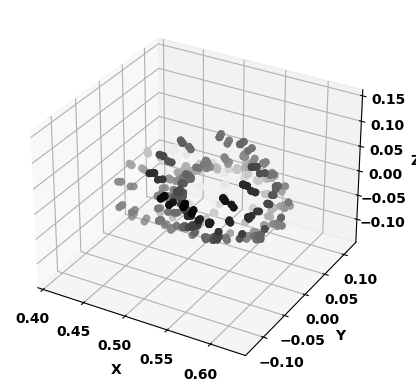

In [106]:
ms.load_new_mesh('data/90degbend-test-object-3.obj')

m = ms.current_mesh()

v_matrix_test_3 = m.vertex_matrix()
plot_vertices(v_matrix_test_3)

cov_mat = 
[[ 0.0031 -0.0014  0.0019]
 [-0.0014  0.0029 -0.002 ]
 [ 0.0019 -0.002   0.0044]]

eg_vec = 
[[ 0.21852638  0.83640035 -0.50267353]
 [ 0.86443667  0.0730848   0.49740111]
 [ 0.45276426 -0.5432247  -0.70704417]]

eg_val = [0.00149855 0.00174366 0.00715779]

primary axis max_extent = 0.17
primary axis min_extent = 0.17

secondary axis skewed max_extent = 0.07
secondary axis skewed min_extent = 0.08

min > max, eg_vec points outward already

rot_matrix = 
[[-0.50267353  0.83640035  0.21852638]
 [ 0.49740111  0.0730848   0.86443667]
 [-0.70704417 -0.5432247   0.45276426]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

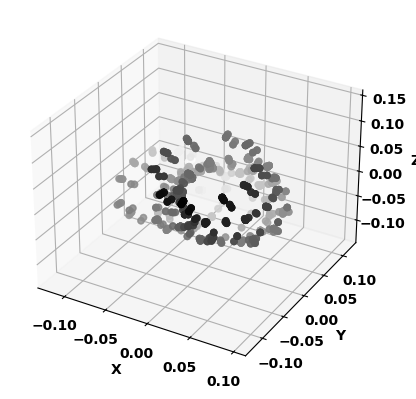

In [107]:
# 0) Center the Vertices
v_matrix_test_norm = v_matrix_test_3 - np.mean(v_matrix_test_3, axis=0)

# 1) Find covariance matrix
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
print(f"cov_mat = \n{cov_mat_test}\n")

# 2) Eigen decomposition
eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
print(f"eg_vec = \n{eg_vec_test}\n")
print(f"eg_val = {eg_val_test}\n")

# 3) Find the correct orientation of 2nd eigenvector
## a) Project all points onto largest eg_vec
proj_test = v_matrix_test_norm @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[0]]

## b) Calculate extents of proj_test
proj_max = np.round(np.max(proj_test),2)
proj_min = abs(np.round(np.min(proj_test),2))
print(f"primary axis max_extent = {proj_max}")
print(f"primary axis min_extent = {proj_min}\n")

## c) Nullify vertices that lie within 25% of the max extent
skew_test = np.where( abs(proj_test[:, None]) > proj_max * 0.25, v_matrix_test_norm, 0 )

## d) Project skewed vertices onto 2nd largest eg_vec
proj_test_skew = skew_test @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[1]]

## e) Determine if max_extent > min_extent and vice versa
skew_max = np.round(np.max(proj_test_skew),2)
skew_min = abs(np.round(np.min(proj_test_skew),2))
print(f"secondary axis skewed max_extent = {skew_max}")
print(f"secondary axis skewed min_extent = {skew_min}\n")

## f) Calculate necessary swap factor
if skew_min > skew_max:
    swap = 1
    print("min > max, eg_vec points outward already\n")
else:
    swap = -1
    print("max > min, eg_vec points inward, swap necessary\n")

# 4) Calculate the rotation matrix
rot_matrix_test = eg_vec_test[:, np.argsort(eg_val_test, descending=True)]
rot_matrix_test[:, 1] = rot_matrix_test[:, 1] * swap
rot_matrix_test[:, 2] = rot_matrix_test[:, 2] * swap
print(f"rot_matrix = \n{rot_matrix_test}\n")

# 5) Multiply input vertices by rotation matrix
transformed_shape = unit_basis @ np.transpose(rot_matrix_test)
plot_vertices(transformed_shape)

I am truly amazed that the transpose fixed the issue. The logic was sound in my head, but why did the transpose fix the problem? More importantly, when we transform our sample shape to its neutral position, we didn't apply any transpose? Why? Guess we'll have to save these answers for another day. For now, one last test- 75 degree rotation.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

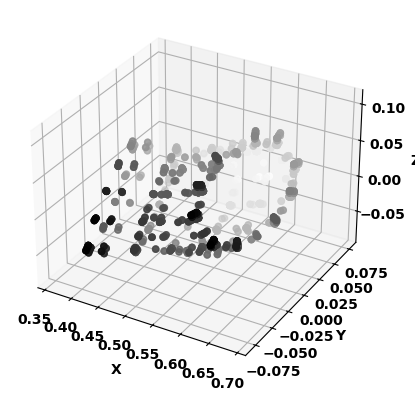

In [108]:
ms.load_new_mesh('data/90degbend-test-object-4.obj')

m = ms.current_mesh()

v_matrix_test_4 = m.vertex_matrix()
plot_vertices(v_matrix_test_4)

cov_mat = 
[[ 0.0069  0.      0.0014]
 [ 0.      0.0016 -0.0001]
 [ 0.0014 -0.0001  0.002 ]]

eg_vec = 
[[ 0.16455806 -0.19712097 -0.96646985]
 [-0.756627   -0.65383109  0.00452652]
 [-0.63280031  0.73051231 -0.25674023]]

eg_val = [0.00151637 0.00171173 0.00727191]

primary axis max_extent = 0.17
primary axis min_extent = 0.17

secondary axis skewed max_extent = 0.08
secondary axis skewed min_extent = 0.07

max > min, eg_vec points inward, swap necessary

rot_matrix = 
[[-0.96646985  0.19712097 -0.16455806]
 [ 0.00452652  0.65383109  0.756627  ]
 [-0.25674023 -0.73051231  0.63280031]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

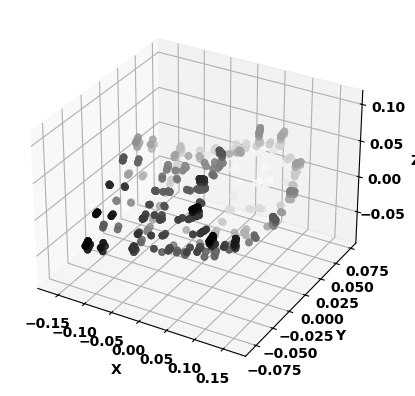

In [109]:
# 0) Center the Vertices
v_matrix_test_norm = v_matrix_test_4 - np.mean(v_matrix_test_4, axis=0)

# 1) Find covariance matrix
cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
print(f"cov_mat = \n{cov_mat_test}\n")

# 2) Eigen decomposition
eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
print(f"eg_vec = \n{eg_vec_test}\n")
print(f"eg_val = {eg_val_test}\n")

# 3) Find the correct orientation of 2nd eigenvector
## a) Project all points onto largest eg_vec
proj_test = v_matrix_test_norm @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[0]]

## b) Calculate extents of proj_test
proj_max = np.round(np.max(proj_test),2)
proj_min = abs(np.round(np.min(proj_test),2))
print(f"primary axis max_extent = {proj_max}")
print(f"primary axis min_extent = {proj_min}\n")

## c) Nullify vertices that lie within 25% of the max extent
skew_test = np.where( abs(proj_test[:, None]) > proj_max * 0.25, v_matrix_test_norm, 0 )

## d) Project skewed vertices onto 2nd largest eg_vec
proj_test_skew = skew_test @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[1]]

## e) Determine if max_extent > min_extent and vice versa
skew_max = np.round(np.max(proj_test_skew),2)
skew_min = abs(np.round(np.min(proj_test_skew),2))
print(f"secondary axis skewed max_extent = {skew_max}")
print(f"secondary axis skewed min_extent = {skew_min}\n")

## f) Calculate necessary swap factor
if skew_min > skew_max:
    swap = 1
    print("min > max, eg_vec points outward already\n")
else:
    swap = -1
    print("max > min, eg_vec points inward, swap necessary\n")

# 4) Calculate the rotation matrix
rot_matrix_test = eg_vec_test[:, np.argsort(eg_val_test, descending=True)]
rot_matrix_test[:, 1] = rot_matrix_test[:, 1] * swap
rot_matrix_test[:, 2] = rot_matrix_test[:, 2] * swap
print(f"rot_matrix = \n{rot_matrix_test}\n")

# 5) Multiply input vertices by rotation matrix
transformed_shape = unit_basis @ np.transpose(rot_matrix_test)
plot_vertices(transformed_shape)

Mesmerizing results.

## Modularizing the Code

Its time to modularize our code and convert it into a repeatable function.

In [114]:
def get_pose_90deg(v_matrix):
    '''
    
    '''
    # 0) Center the Vertices
    v_matrix_test_norm = v_matrix - np.mean(v_matrix, axis=0)

    # 1) Find covariance matrix
    cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
    print(f"cov_mat = \n{cov_mat_test}\n")

    # 2) Eigen decomposition
    eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
    print(f"eg_vec = \n{eg_vec_test}\n")
    print(f"eg_val = {eg_val_test}\n")

    # 3) Find the correct orientation of 2nd eigenvector
    ## a) Project all points onto largest eg_vec
    proj_test = v_matrix_test_norm @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[0]]

    ## b) Calculate extents of proj_test
    proj_max = np.round(np.max(proj_test),2)
    proj_min = abs(np.round(np.min(proj_test),2))
    print(f"primary axis max_extent = {proj_max}")
    print(f"primary axis min_extent = {proj_min}\n")

    ## c) Nullify vertices that lie within 25% of the max extent
    skew_test = np.where( abs(proj_test[:, None]) > proj_max * 0.25, v_matrix_test_norm, 0 )

    ## d) Project skewed vertices onto 2nd largest eg_vec
    proj_test_skew = skew_test @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[1]]

    ## e) Determine if max_extent > min_extent and vice versa
    skew_max = np.round(np.max(proj_test_skew),2)
    skew_min = abs(np.round(np.min(proj_test_skew),2))
    print(f"secondary axis skewed max_extent = {skew_max}")
    print(f"secondary axis skewed min_extent = {skew_min}\n")

    ## f) Calculate necessary swap factor
    if skew_min > skew_max:
        swap = 1
        print("min > max, eg_vec points outward already\n")
    else:
        swap = -1
        print("max > min, eg_vec points inward, swap necessary\n")

    # 4) Calculate the rotation matrix
    rot_matrix_test = eg_vec_test[:, np.argsort(eg_val_test, descending=True)]
    rot_matrix_test[:, 1] = rot_matrix_test[:, 1] * swap
    rot_matrix_test[:, 2] = rot_matrix_test[:, 2] * swap
    print(f"rot_matrix = \n{np.transpose(rot_matrix_test)}\n")

    return np.transpose(rot_matrix_test)

To confirm that its working as intended, lets conduct one more test.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

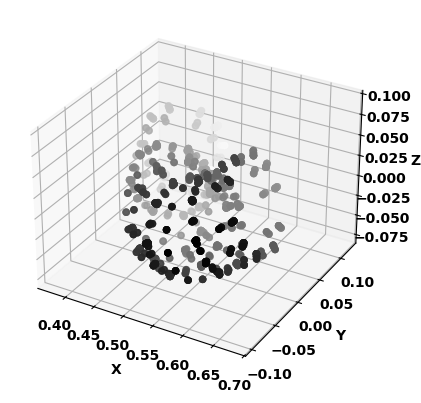

In [115]:
ms.load_new_mesh('data/90degbend-test-object-5.obj')

m = ms.current_mesh()

v_matrix_test_5 = m.vertex_matrix()
plot_vertices(v_matrix_test_5)

cov_mat = 
[[ 0.0058 -0.0023  0.0007]
 [-0.0023  0.003  -0.0003]
 [ 0.0007 -0.0003  0.0017]]

eg_vec = 
[[-0.33194432  0.37720962 -0.86459579]
 [-0.34577089  0.80411359  0.48357402]
 [ 0.87764199  0.4594717  -0.13649283]]

eg_val = [0.00155344 0.00174965 0.00719691]

primary axis max_extent = 0.17
primary axis min_extent = 0.17

secondary axis skewed max_extent = 0.08
secondary axis skewed min_extent = 0.07

max > min, eg_vec points inward, swap necessary

rot_matrix = 
[[-0.86459579  0.48357402 -0.13649283]
 [-0.37720962 -0.80411359 -0.4594717 ]
 [ 0.33194432  0.34577089 -0.87764199]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

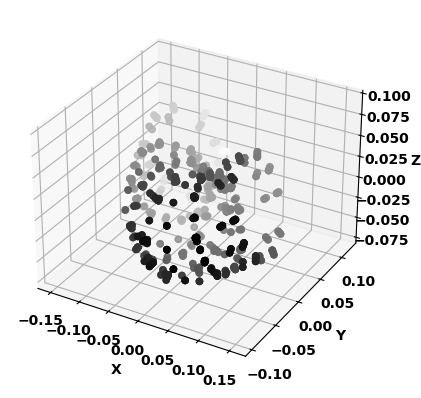

In [116]:
transformed_v_matrix_test_5 = unit_basis @ get_pose_90deg(v_matrix_test_5)
plot_vertices(transformed_v_matrix_test_5)

Working as intended.

## Testing on Non Exact Shapes

As we've seen in the first figure, we have multiple types of 90 degree bends. All should have the same general shape, but the geometry of each would be different. Let's test out our function against some of these and see if it performs.

### Test 1: Thin object

This object is noticeably thinner than our sample. Lets see how it performs.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

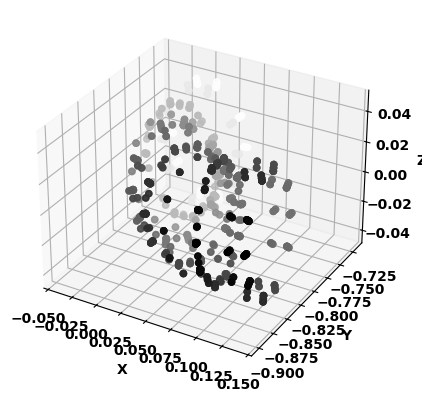

In [117]:
ms.load_new_mesh('data/90degbend-test-object-6.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
plot_vertices(v_matrix_test)

cov_mat = 
[[ 0.0025 -0.0017  0.0001]
 [-0.0017  0.0026 -0.0001]
 [ 0.0001 -0.0001  0.0007]]

eg_vec = 
[[-0.03729447  0.71697313 -0.69610247]
 [ 0.01915958  0.69697205  0.71684229]
 [ 0.99912063  0.01339722 -0.03973011]]

eg_val = [0.00069435 0.00084929 0.00425636]

primary axis max_extent = 0.13
primary axis min_extent = 0.13

secondary axis skewed max_extent = 0.06
secondary axis skewed min_extent = 0.05

max > min, eg_vec points inward, swap necessary

rot_matrix = 
[[-0.69610247  0.71684229 -0.03973011]
 [-0.71697313 -0.69697205 -0.01339722]
 [ 0.03729447 -0.01915958 -0.99912063]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

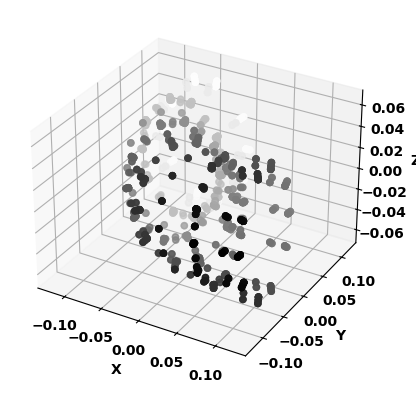

In [118]:
transformed_v_matrix_test = unit_basis @ get_pose_90deg(v_matrix_test)
plot_vertices(transformed_v_matrix_test)

Looks good. Test passed.

### Test 2: Stumpy Object

This 90 degree bend is short and stumpy.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

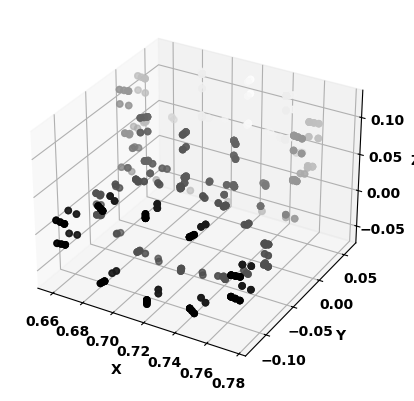

In [138]:
ms.load_new_mesh('data/90degbend-test-object-7.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
plot_vertices(v_matrix_test)

cov_mat = 
[[0.0015 0.     0.    ]
 [0.     0.0031 0.0018]
 [0.     0.0018 0.0031]]

eg_vec = 
[[ 0.          1.          0.        ]
 [-0.70710678  0.          0.70710678]
 [ 0.70710678  0.          0.70710678]]

eg_val = [0.0013 0.0015 0.0049]

primary axis max_extent = 0.13
primary axis min_extent = 0.13

secondary axis skewed max_extent = 0.06
secondary axis skewed min_extent = 0.06

min > max, eg_vec points outward already

rot_matrix = 
[[ 0.          0.70710678  0.70710678]
 [ 1.          0.          0.        ]
 [ 0.         -0.70710678  0.70710678]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

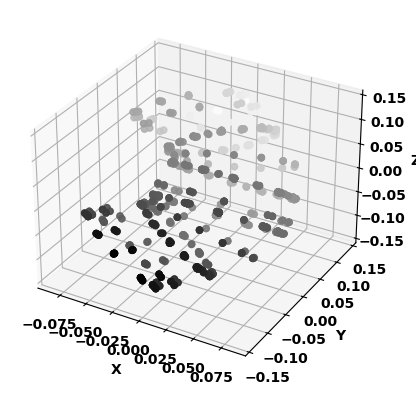

In [140]:
transformed_v_matrix_test = unit_basis @ get_pose_90deg(v_matrix_test, 0.15)
plot_vertices(transformed_v_matrix_test)

This looks like a fail. Since the object is stumpy, our skewed extents dont seem to be calculating properly. Perhaps adding a threshold to our function might help. Lets also remove the rounding we conduct when calculating the extents.

In [136]:
def get_pose_90deg(v_matrix, threshold):
    '''
    
    '''
    # 0) Center the Vertices
    v_matrix_test_norm = v_matrix - np.mean(v_matrix, axis=0)

    # 1) Find covariance matrix
    cov_mat_test = np.round(np.cov(v_matrix_test_norm, rowvar=False),4)
    print(f"cov_mat = \n{cov_mat_test}\n")

    # 2) Eigen decomposition
    eg_val_test, eg_vec_test = np.linalg.eigh(cov_mat_test)
    print(f"eg_vec = \n{eg_vec_test}\n")
    print(f"eg_val = {eg_val_test}\n")

    # 3) Find the correct orientation of 2nd eigenvector
    ## a) Project all points onto largest eg_vec
    proj_test = v_matrix_test_norm @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[0]]

    ## b) Calculate extents of proj_test
    proj_max = np.round(np.max(proj_test),2)
    proj_min = abs(np.round(np.min(proj_test),2))
    print(f"primary axis max_extent = {proj_max}")
    print(f"primary axis min_extent = {proj_min}\n")

    ## c) Nullify vertices that lie within 25% of the max extent
    skew_test = np.where( abs(proj_test[:, None]) > proj_max * threshold, v_matrix_test_norm, 0 )

    ## d) Project skewed vertices onto 2nd largest eg_vec
    proj_test_skew = skew_test @ eg_vec_test[:, np.argsort(eg_val_test, descending=True)[1]]

    ## e) Determine if max_extent > min_extent and vice versa
    skew_max = np.max(proj_test_skew)
    skew_min = abs(np.min(proj_test_skew))
    print(f"secondary axis skewed max_extent = {np.round(skew_max, 2)}")
    print(f"secondary axis skewed min_extent = {np.round(skew_min, 2)}\n")

    ## f) Calculate necessary swap factor
    if skew_min > skew_max:
        swap = 1
        print("min > max, eg_vec points outward already\n")
    else:
        swap = -1
        print("max > min, eg_vec points inward, swap necessary\n")

    # 4) Calculate the rotation matrix
    rot_matrix_test = eg_vec_test[:, np.argsort(eg_val_test, descending=True)]
    rot_matrix_test[:, 1] = rot_matrix_test[:, 1] * swap
    rot_matrix_test[:, 2] = rot_matrix_test[:, 2] * swap
    print(f"rot_matrix = \n{np.transpose(rot_matrix_test)}\n")

    return np.transpose(rot_matrix_test)

cov_mat = 
[[0.0015 0.     0.    ]
 [0.     0.0031 0.0018]
 [0.     0.0018 0.0031]]

eg_vec = 
[[ 0.          1.          0.        ]
 [-0.70710678  0.          0.70710678]
 [ 0.70710678  0.          0.70710678]]

eg_val = [0.0013 0.0015 0.0049]

primary axis max_extent = 0.13
primary axis min_extent = 0.13

secondary axis skewed max_extent = 0.06
secondary axis skewed min_extent = 0.06

min > max, eg_vec points outward already

rot_matrix = 
[[ 0.          0.70710678  0.70710678]
 [ 1.          0.          0.        ]
 [ 0.         -0.70710678  0.70710678]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

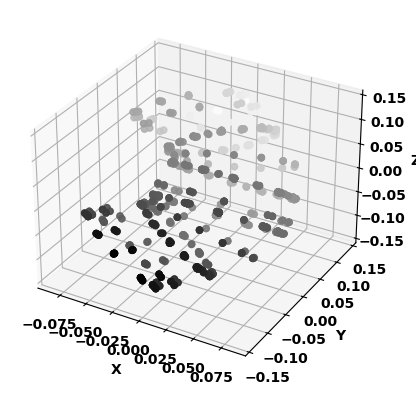

In [141]:
transformed_v_matrix_test = unit_basis @ get_pose_90deg(v_matrix_test, 0.15)
plot_vertices(transformed_v_matrix_test)

Perhaps we'll come back to the short and stubby one. Test FAILED.

### Test 3: Short, but less Stubby

This object is short as well, but looks less stubby than our earlier one.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

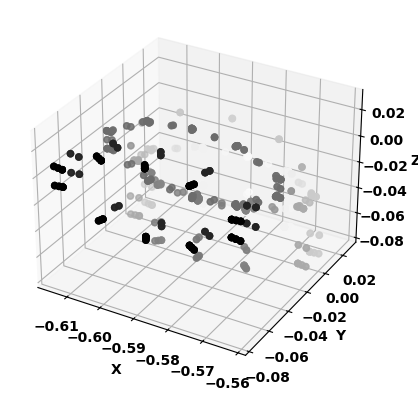

In [130]:
ms.load_new_mesh('data/90degbend-test-object-8.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
plot_vertices(v_matrix_test)

cov_mat = 
[[ 0.0003 -0.      0.    ]
 [-0.      0.001  -0.0006]
 [ 0.     -0.0006  0.001 ]]

eg_vec = 
[[ 1.         -0.          0.        ]
 [ 0.         -0.70710678 -0.70710678]
 [ 0.         -0.70710678  0.70710678]]

eg_val = [0.0003 0.0004 0.0016]

primary axis max_extent = 0.07
primary axis min_extent = 0.07

secondary axis skewed max_extent = 0.03837257462929132
secondary axis skewed min_extent = 0.03079166095890845

max > min, eg_vec points inward, swap necessary

rot_matrix = 
[[ 0.         -0.70710678  0.70710678]
 [ 0.          0.70710678  0.70710678]
 [-1.         -0.         -0.        ]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

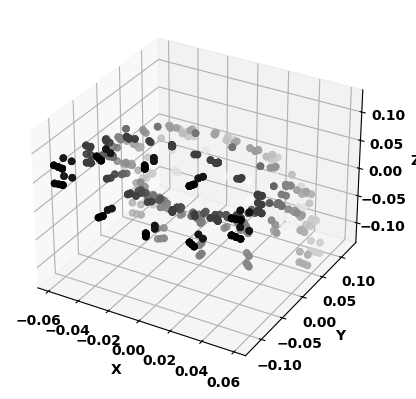

In [131]:
transformed_v_matrix_test = unit_basis @ get_pose_90deg(v_matrix_test, 0.15)
plot_vertices(transformed_v_matrix_test)

This one seems to have worked. Test passed.

## Test 4: Short and Stubby without Flanges

All our objects so far have had flanges at their ends (an outward flay to the pipe). This one is as close to an ideal 90degree bend as there is.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

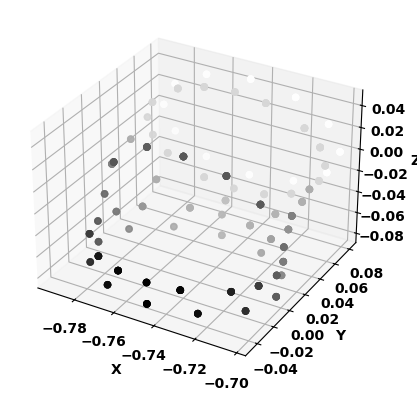

In [142]:
ms.load_new_mesh('data/90degbend-test-object-9.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
plot_vertices(v_matrix_test)

cov_mat = 
[[ 0.0011  0.     -0.    ]
 [ 0.      0.0014  0.0007]
 [-0.      0.0007  0.0015]]

eg_vec = 
[[ 0.          1.          0.        ]
 [-0.73186305  0.          0.68145174]
 [ 0.68145174  0.          0.73186305]]

eg_val = [0.00074822 0.0011     0.00215178]

primary axis max_extent = 0.09
primary axis min_extent = 0.09

secondary axis skewed max_extent = 0.04
secondary axis skewed min_extent = 0.05

min > max, eg_vec points outward already

rot_matrix = 
[[ 0.          0.68145174  0.73186305]
 [ 1.          0.          0.        ]
 [ 0.         -0.73186305  0.68145174]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

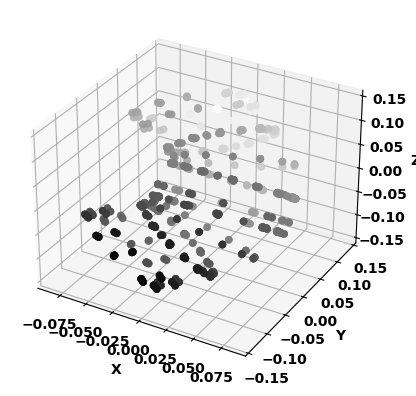

In [143]:
transformed_v_matrix_test = unit_basis @ get_pose_90deg(v_matrix_test, 0.15)
plot_vertices(transformed_v_matrix_test)

Once again, this seems to have failed. I reckon its because the dimensions of our object along the longest and second long axis are closely aligned, meaning our algorithm cannot definitively tell if our axis is correctly aligned or not. TEST FAILED.

### Test 5: Another Short and Stubby

Since we haven't had enough short and stubby ones, lets add another.

<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

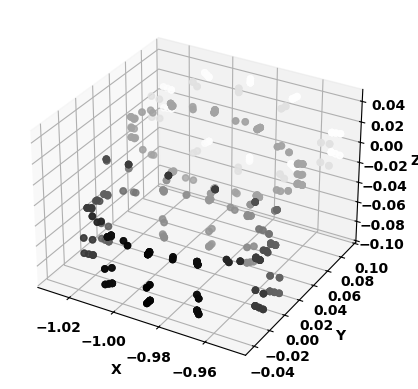

In [134]:
ms.load_new_mesh('data/90degbend-test-object-10.obj')

m = ms.current_mesh()

v_matrix_test = m.vertex_matrix()
plot_vertices(v_matrix_test)

cov_mat = 
[[0.0007 0.     0.    ]
 [0.     0.0016 0.0009]
 [0.     0.0009 0.0016]]

eg_vec = 
[[ 1.          0.          0.        ]
 [ 0.         -0.70710678  0.70710678]
 [ 0.          0.70710678  0.70710678]]

eg_val = [0.0007 0.0007 0.0025]

primary axis max_extent = 0.09
primary axis min_extent = 0.09

secondary axis skewed max_extent = 0.040291548968307396
secondary axis skewed min_extent = 0.05016084337429457

min > max, eg_vec points outward already

rot_matrix = 
[[ 0.          0.70710678  0.70710678]
 [ 0.         -0.70710678  0.70710678]
 [ 1.          0.          0.        ]]



<Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>

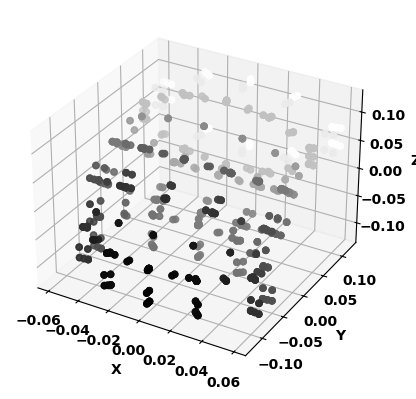

In [135]:
transformed_v_matrix_test = unit_basis @ get_pose_90deg(v_matrix_test, 0.15)
plot_vertices(transformed_v_matrix_test)

This one seems to have worked well.

## Results and Conclusion

We're reaching the limits of my brainpower here. Our algorithm seems to work well on long, defined 90 degree bend object, and seems to fail on the shorter and stubbier ones. Further steps could be taken to identfy the correct axis- like taking a cross section of our object at the centroid and seeing its shape. This could help us more definitively find the correct orientation for our eigenvectors.

At this point, our notebook is definitely getting way too large. Let's table this for another day. For now, we have a definitive way of instancing a majority (hopefully) of 90 degree bends in the model, which should theoretically improve the memory consumption of the scene, and final file by quite a lot.